In [1]:
%pip install numpy pandas matplotlib seaborn pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

dataset_path = "spotify_top_1000_tracks.csv"

df = pd.read_csv(dataset_path, encoding="utf-8")

print("Dataset loaded successfully!")
print(df.head(3))

Dataset loaded successfully!
                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9YMctZqd1...  7MXVkk9YMctZqd1Srtv4MB   
2  https://open.spotify.com/track/0TK2YIli7K1leLo...  0TK2YIli7K1leLovkQiNik   

   duration_min  
0      3.869767  
1      3.840883  
2      3.182667  


In [3]:
print(df.columns)

Index(['track_name', 'artist', 'album', 'release_date', 'popularity',
       'spotify_url', 'id', 'duration_min'],
      dtype='str')


In [4]:
# Clean text columns
df['track_name'] = df['track_name'].str.strip()
df['artist'] = df['artist'].str.strip()
df['album'] = df['album'].str.strip()

# Convert release date
df['release_date'] = pd.to_datetime(
    df['release_date'], errors='coerce'
)

# Extract release year
df['release_year'] = df['release_date'].dt.year

# Create decade
df['decade'] = (df['release_year'] // 10) * 10

# Remove duplicate songs
df = df.drop_duplicates(
    subset=['track_name', 'artist'],
    keep='first'
)

print("Data cleaning completed!")
print("Final Row Count:", len(df))
print(df.head(3))

Data cleaning completed!
Final Row Count: 971
                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9YMctZqd1...  7MXVkk9YMctZqd1Srtv4MB   
2  https://open.spotify.com/track/0TK2YIli7K1leLo...  0TK2YIli7K1leLovkQiNik   

   duration_min  release_year  decade  
0      3.869767        2018.0  2010.0  
1      3.840883        2016.0  2010.0  

In [5]:
student_name = "Pena"
student_id = "TUPM-26-1140"

id_num = int(student_id[-3:])

color1 = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"

color2 = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4) % 256:02x}"

print("Student:", student_name)
print("Student ID:", student_id)
print("Color 1:", color1)
print("Color 2:", color2)

Student: Pena
Student ID: TUPM-26-1140
Color 1: #d4a4bc
Color 2: #18ec30


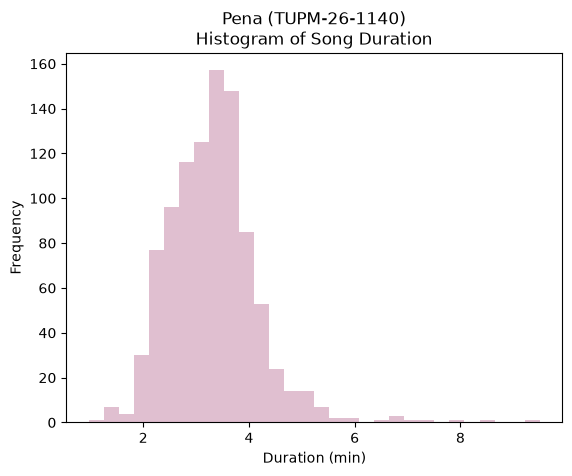

In [6]:
df['duration_min'].plot(
    kind='hist',
    bins=30,
    color=color1,
    alpha=0.7
)

plt.title(
    f"{student_name} ({student_id})\nHistogram of Song Duration"
)
plt.xlabel('Duration (min)')
plt.ylabel('Frequency')
plt.show()

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('spotify_top_1000_tracks.csv')

In [7]:
df.head()

,track_name,artist,album,release_date,popularity,spotify_url,id,duration_min
0,All The Stars (with SZA),Kendrick Lamar,Black Panther The Album Music From And Inspire...,2018-02-09,95,https://open.spotify.com/track/3GCdLUSnKSMJhs4...,3GCdLUSnKSMJhs4Tj6CV3s,3.869767
1,Starboy,The Weeknd,Starboy,2016-11-25,90,https://open.spotify.com/track/7MXVkk9YMctZqd1...,7MXVkk9YMctZqd1Srtv4MB,3.840883
2,Señorita,Shawn Mendes,Señorita,2019-06-21,80,https://open.spotify.com/track/0TK2YIli7K1leLo...,0TK2YIli7K1leLovkQiNik,3.182667
3,Heat Waves,Glass Animals,Dreamland,2020-08-07,87,https://open.spotify.com/track/3USxtqRwSYz57Ew...,3USxtqRwSYz57Ewm6wWRMp,3.980083
4,Let Me Love You,DJ Snake,Encore,2016-08-05,87,https://open.spotify.com/track/0lYBSQXN6rCTvUZ...,0lYBSQXN6rCTvUZvg9S0lU,3.432433


C:\Users\maryg\AppData\Local\Temp\ipykernel_11532\201224399.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


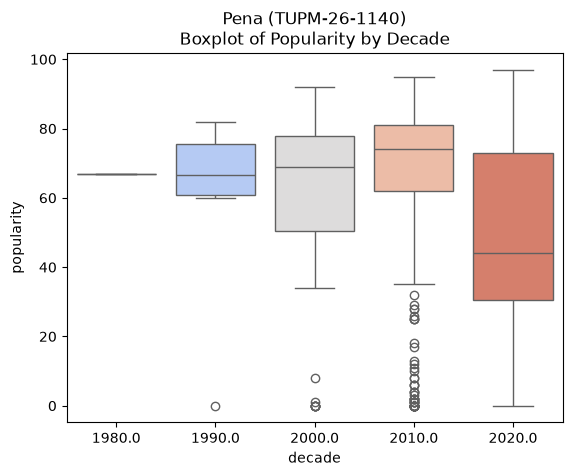

In [7]:
sns.boxplot(
    x='decade',
    y='popularity',
    data=df,
    palette='coolwarm'
)

plt.title(
    f"{student_name} ({student_id})\nBoxplot of Popularity by Decade"
)
plt.show()

C:\Users\maryg\AppData\Local\Temp\ipykernel_11532\1615895852.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


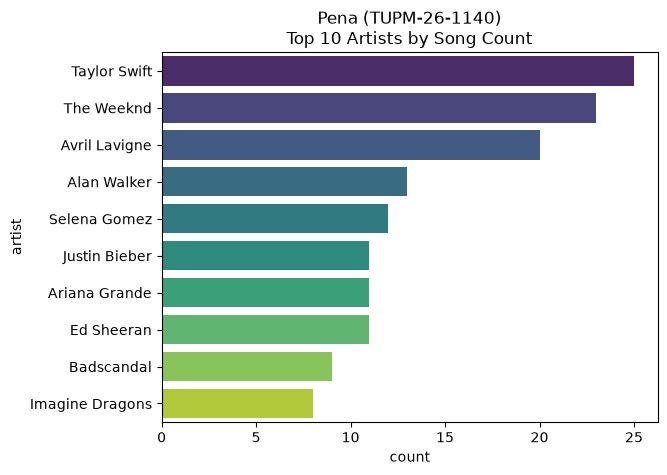

In [8]:
sns.countplot(
    y='artist',
    data=df,
    order=df['artist'].value_counts().head(10).index,
    palette='viridis'
)

plt.title(
    f"{student_name} ({student_id})\nTop 10 Artists by Song Count"
)
plt.show()

C:\Users\maryg\AppData\Local\Temp\ipykernel_25976\2969522597.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='decade', y='popularity', data=df, palette='coolwarm')


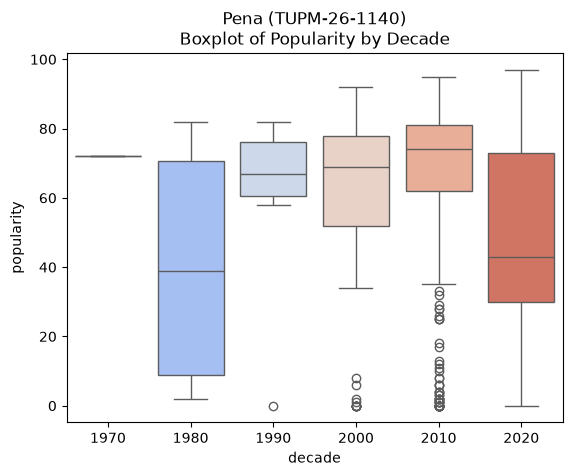

In [13]:
student_name = "Pena"
student_id = "TUPM-26-1140"

df['release_year'] = pd.to_datetime(
    df['release_date'], format='mixed', errors='coerce'
).dt.year

df['decade'] = (df['release_year'] // 10) * 10

sns.boxplot(x='decade', y='popularity', data=df, palette='coolwarm')

plt.title(f"{student_name} ({student_id})\nBoxplot of Popularity by Decade")

plt.show()

C:\Users\maryg\AppData\Local\Temp\ipykernel_11532\770398646.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\maryg\AppData\Local\Temp\ipykernel_11532\770398646.py:1: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


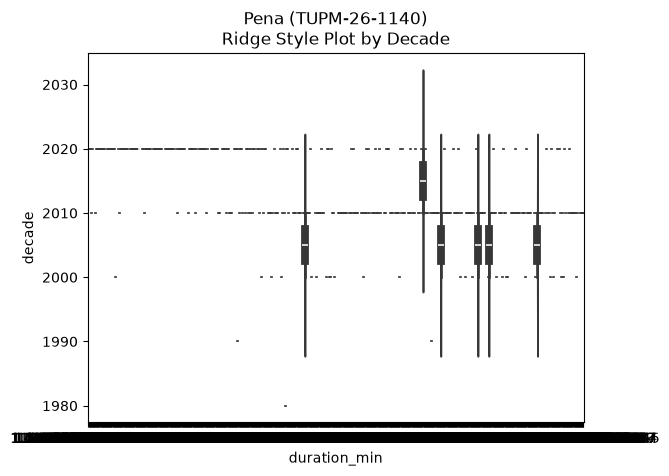

In [9]:
sns.violinplot(
    data=df,
    x='duration_min',
    y='decade',
    palette='coolwarm',
    scale='width'
)

plt.title(
    f"{student_name} ({student_id})\nRidge Style Plot by Decade"
)
plt.show()

C:\Users\maryg\AppData\Local\Temp\ipykernel_11532\770398646.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\maryg\AppData\Local\Temp\ipykernel_11532\770398646.py:1: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


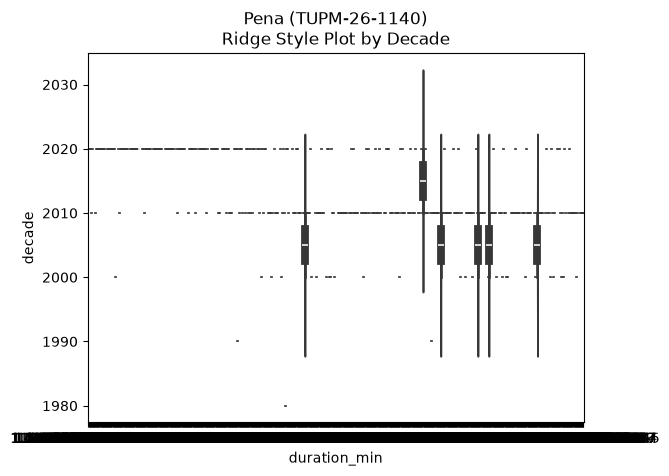

In [10]:
sns.violinplot(
    data=df,
    x='duration_min',
    y='decade',
    palette='coolwarm',
    scale='width'
)

plt.title(
    f"{student_name} ({student_id})\nRidge Style Plot by Decade"
)
plt.show()

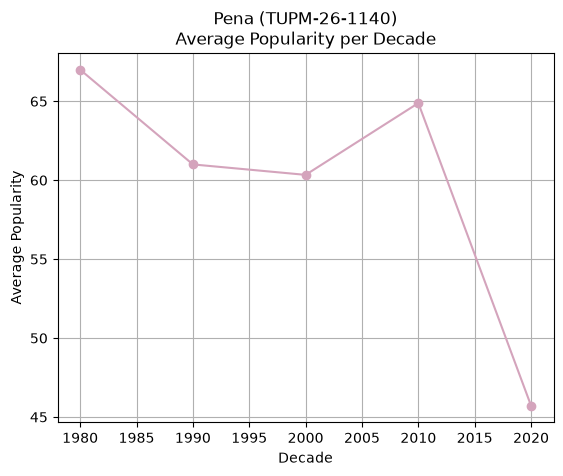

In [11]:
avg_pop = df.groupby('decade')['popularity'].mean()

avg_pop.plot(
    kind='line',
    color=color1,
    marker='o'
)

plt.title(
    f"{student_name} ({student_id})\nAverage Popularity per Decade"
)
plt.xlabel('Decade')
plt.ylabel('Average Popularity')
plt.grid(True)
plt.show()

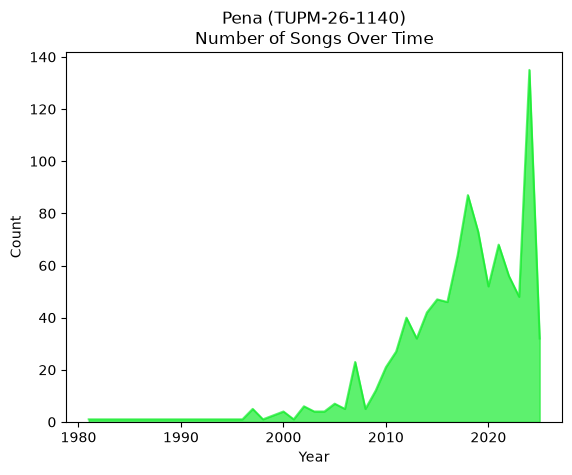

In [12]:
df['release_year'] = pd.to_datetime(
    df['release_date'],
    errors='coerce'
).dt.year

count_by_year = df['release_year'].value_counts().sort_index()

count_by_year.plot(
    kind='area',
    color=color2,
    alpha=0.7
)

plt.title(
    f"{student_name} ({student_id})\nNumber of Songs Over Time"
)
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()

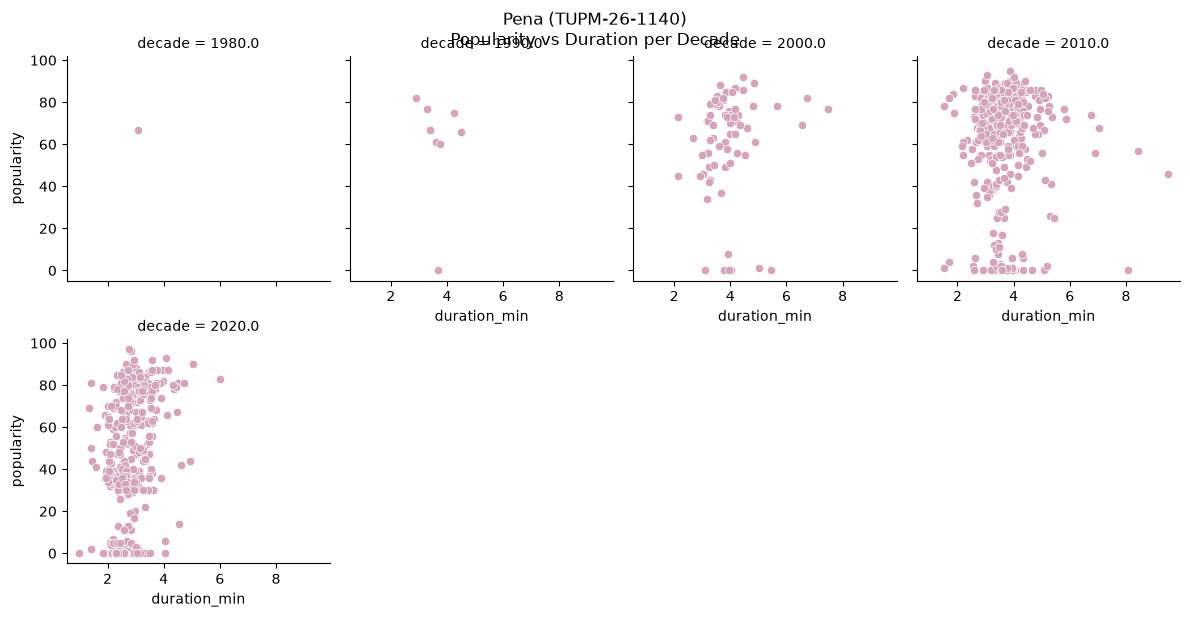

In [13]:
g = sns.FacetGrid(
    df,
    col='decade',
    col_wrap=4,
    height=3
)

g.map_dataframe(
    sns.scatterplot,
    x='duration_min',
    y='popularity',
    color=color1
)

g.fig.suptitle(
    f"{student_name} ({student_id})\nPopularity vs Duration per Decade",
    y=1.02
)

plt.show()

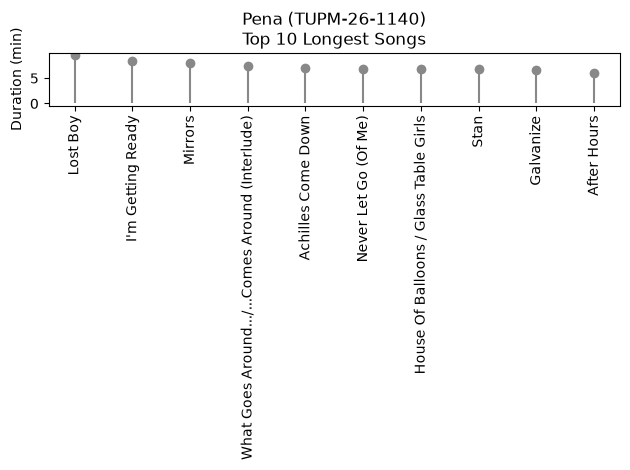

In [14]:
longest = df.nlargest(10, 'duration_min')

plt.stem(
    longest['track_name'],
    longest['duration_min'],
    linefmt='#888888',
    markerfmt='o',
    basefmt=" "
)

plt.xticks(rotation=90)

plt.title(
    f"{student_name} ({student_id})\nTop 10 Longest Songs"
)

plt.ylabel('Duration (min)')
plt.tight_layout()
plt.show()

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


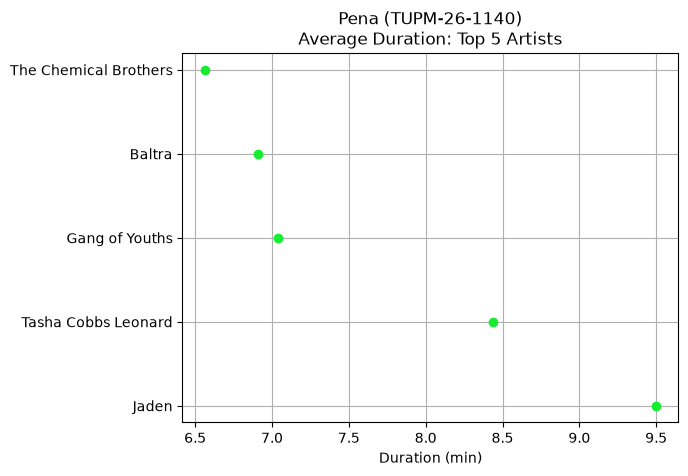

In [15]:
avg_duration = df.groupby('artist')['duration_min'].mean().nlargest(5)

plt.plot(
    avg_duration.values,
    avg_duration.index,
    'o',
    color=color2
)

plt.title(
    f"{student_name} ({student_id})\nAverage Duration: Top 5 Artists"
)

plt.xlabel('Duration (min)')
plt.grid(True)
plt.show()

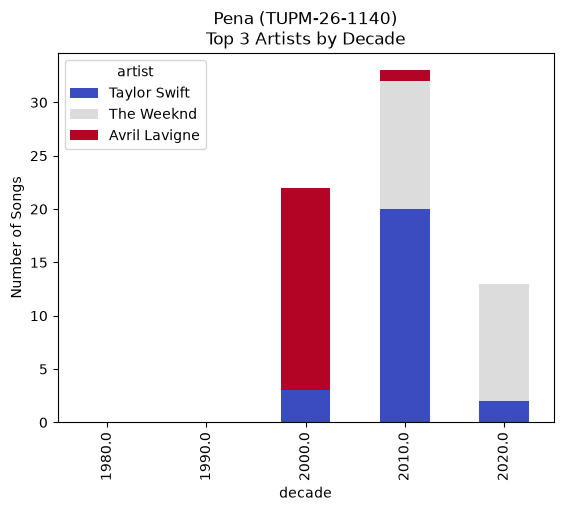

In [16]:
crosstab = pd.crosstab(df['decade'], df['artist'])

top3 = df['artist'].value_counts().head(3).index

crosstab[top3].plot(
    kind='bar',
    stacked=True,
    colormap='coolwarm'
)

plt.title(
    f"{student_name} ({student_id})\nTop 3 Artists by Decade"
)

plt.ylabel('Number of Songs')
plt.show()

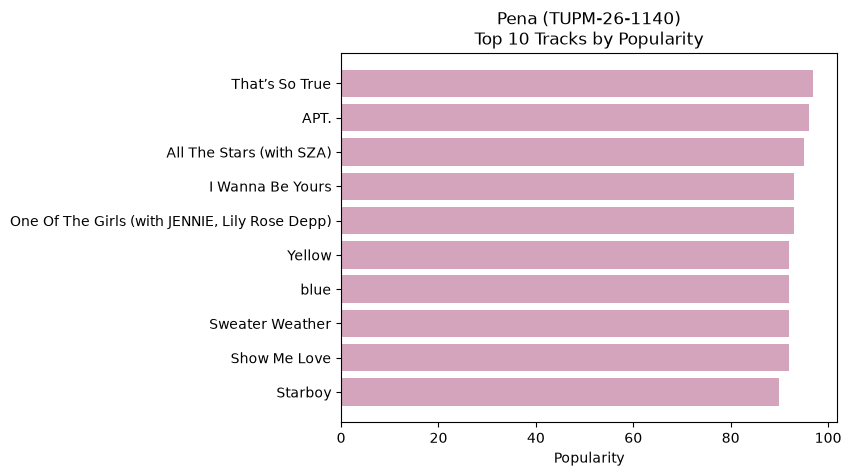

In [17]:
top_tracks = df.nlargest(10, 'popularity')

plt.barh(
    top_tracks['track_name'],
    top_tracks['popularity'],
    color=color1
)

plt.xlabel('Popularity')

plt.title(
    f"{student_name} ({student_id})\nTop 10 Tracks by Popularity"
)

plt.gca().invert_yaxis()
plt.show()

C:\Users\maryg\AppData\Local\Temp\ipykernel_11532\3042395769.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\maryg\AppData\Local\Temp\ipykernel_11532\3042395769.py:3: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.stripplot(


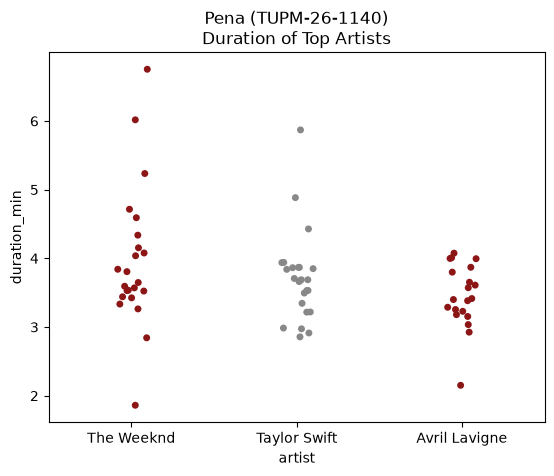

In [18]:
top_artists = df['artist'].value_counts().head(3).index

sns.stripplot(
    data=df[df['artist'].isin(top_artists)],
    x='artist',
    y='duration_min',
    palette=['#8C1515', '#888888']
)

plt.title(
    f"{student_name} ({student_id})\nDuration of Top Artists"
)

plt.show()

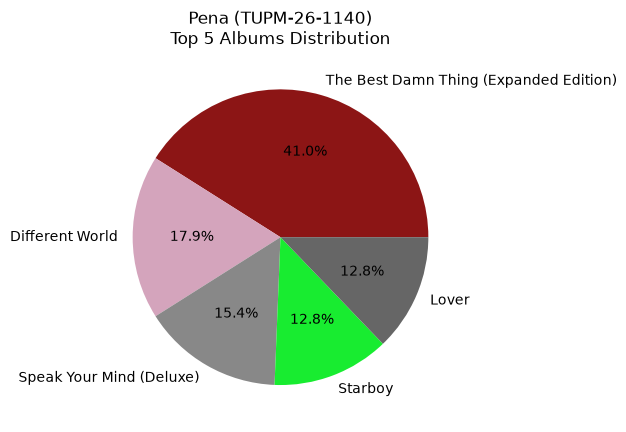

In [19]:
top_albums = df['album'].value_counts().head(5)

colors = ['#8C1515', color1, '#888888', color2, '#666666']

plt.pie(
    top_albums,
    labels=top_albums.index,
    autopct='%1.1f%%',
    colors=colors
)

plt.title(
    f"{student_name} ({student_id})\nTop 5 Albums Distribution"
)

plt.show()

In [20]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
import sys

print("Python location:")
print(sys.executable)

try:
    import scipy
    print("SciPy version:", scipy.__version__)
except ImportError as e:
    print("SciPy is NOT installed:", e)

Python location:
c:\Users\maryg\AppData\Local\Python\pythoncore-3.14-64\python.exe
SciPy version: 1.18.1


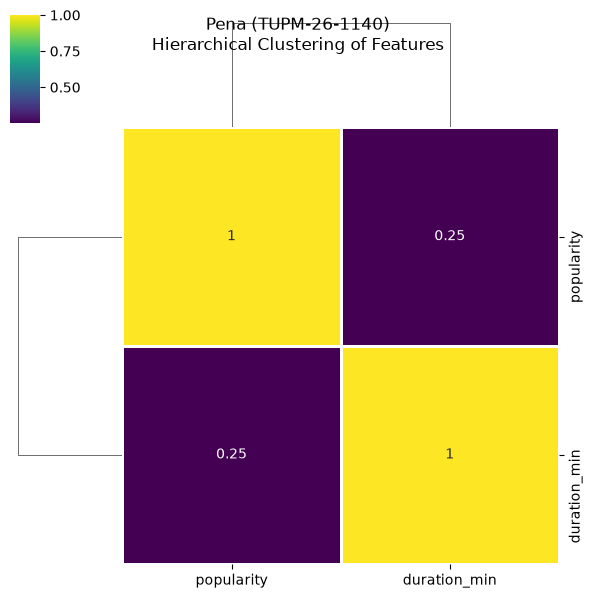

In [22]:
numerical_cols = ['popularity', 'duration_min']

df_numeric = df[numerical_cols].dropna()

sns.clustermap(
    df_numeric.corr(),
    annot=True,
    cmap='viridis',
    linewidths=.75,
    figsize=(6, 6)
)

plt.suptitle(
    f"{student_name} ({student_id})\nHierarchical Clustering of Features"
)

plt.show()

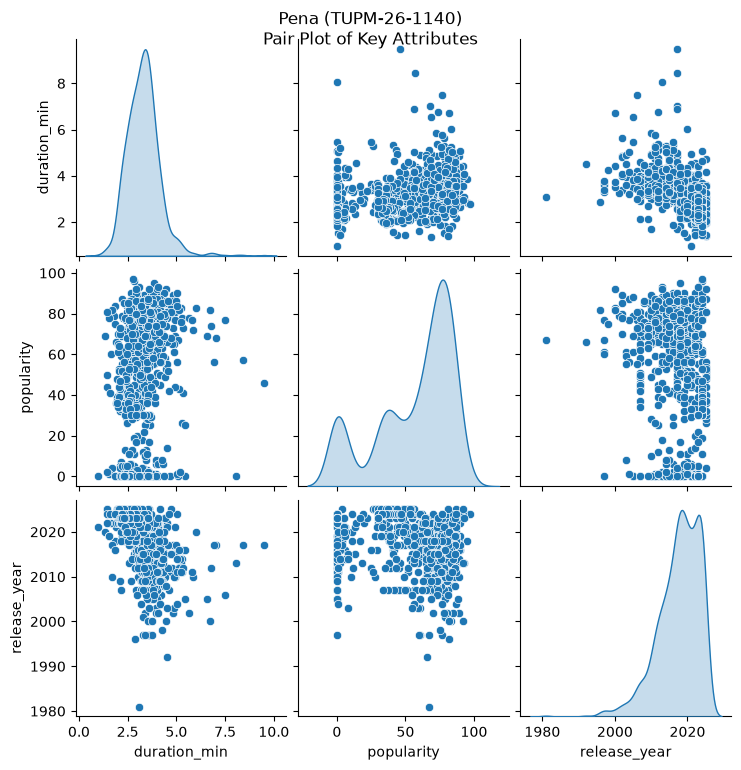

In [23]:
sns.pairplot(
    df[['duration_min', 'popularity', 'release_year']].dropna(),
    diag_kind='kde'
)

plt.suptitle(
    f"{student_name} ({student_id})\nPair Plot of Key Attributes",
    y=1.02
)

plt.show()

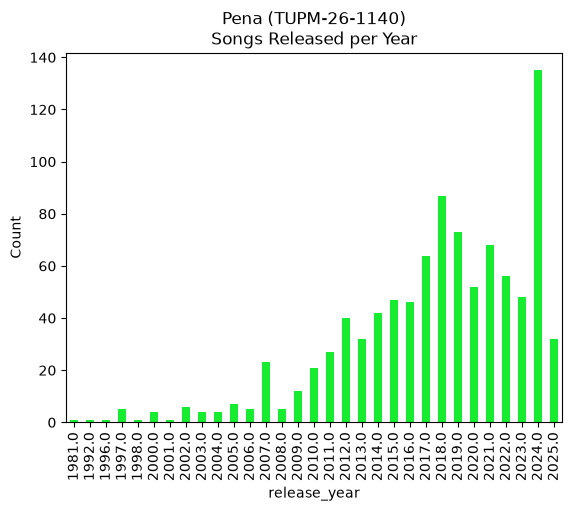

In [24]:
df['release_year'].value_counts().sort_index().plot(
    kind='bar',
    color=color2
)

plt.title(
    f"{student_name} ({student_id})\nSongs Released per Year"
)

plt.ylabel('Count')
plt.show()

C:\Users\maryg\AppData\Local\Temp\ipykernel_11532\3772354516.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


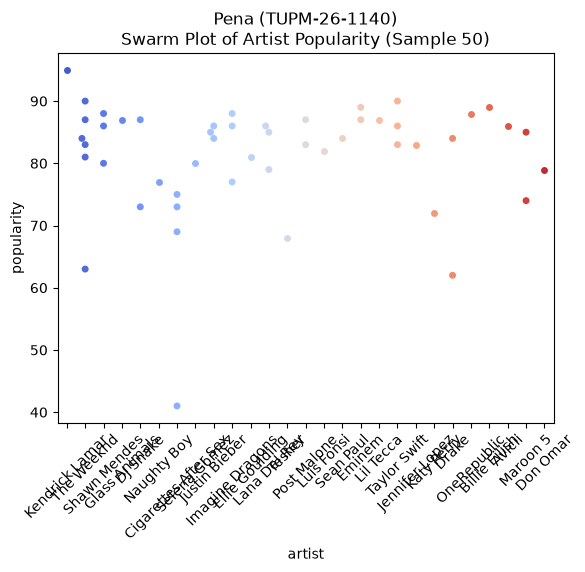

In [25]:
sns.swarmplot(
    data=df.head(50),
    x='artist',
    y='popularity',
    palette='coolwarm'
)

plt.title(
    f"{student_name} ({student_id})\nSwarm Plot of Artist Popularity (Sample 50)"
)

plt.xticks(rotation=45)
plt.show()

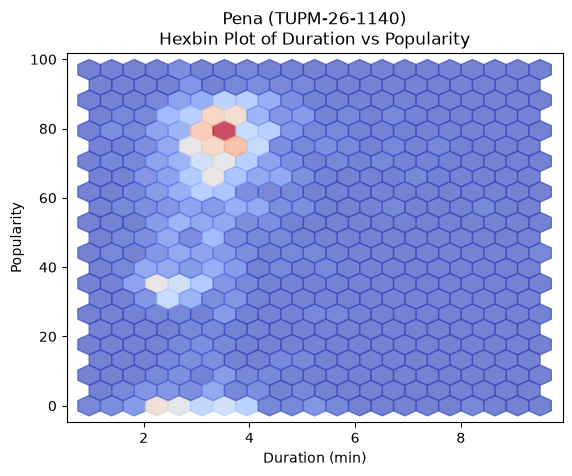

In [26]:
plt.hexbin(
    df['duration_min'],
    df['popularity'],
    gridsize=20,
    cmap='coolwarm',
    alpha=0.7
)

plt.xlabel('Duration (min)')
plt.ylabel('Popularity')

plt.title(
    f"{student_name} ({student_id})\nHexbin Plot of Duration vs Popularity"
)

plt.show()

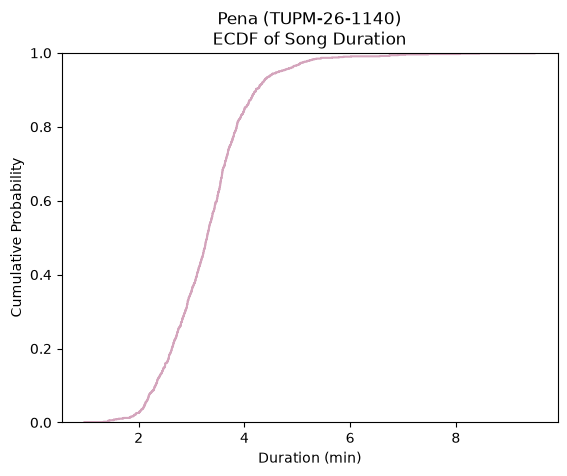

In [27]:
sns.ecdfplot(
    data=df,
    x='duration_min',
    color=color1
)

plt.title(
    f"{student_name} ({student_id})\nECDF of Song Duration"
)

plt.xlabel('Duration (min)')
plt.ylabel('Cumulative Probability')
plt.show()

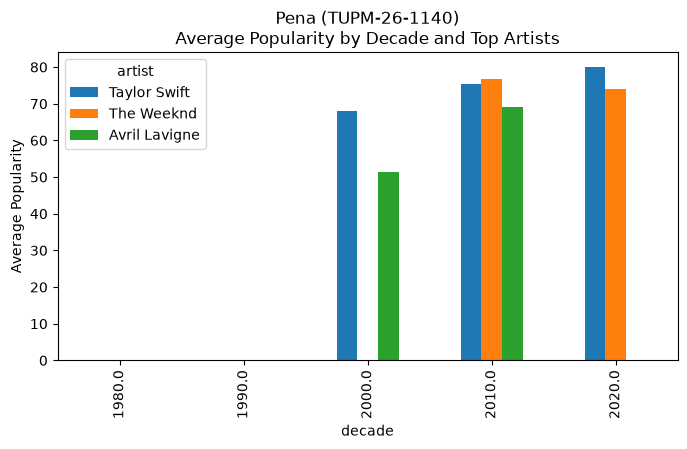

In [28]:
top3 = df['artist'].value_counts().head(3).index

avg_artist_decade = (
    df.groupby(['decade', 'artist'])['popularity']
    .mean()
    .unstack()
    .fillna(0)
)

avg_artist_decade[top3].plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title(
    f"{student_name} ({student_id})\nAverage Popularity by Decade and Top Artists"
)

plt.ylabel('Average Popularity')
plt.show()

In [30]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import webbrowser

# Step 1: Load Dataset
df_anim = pd.read_csv(
    "spotify_top_1000_tracks.csv"
)

# Step 2: Data Preparation
df_anim['release_date'] = pd.to_datetime(
    df_anim['release_date'],
    errors='coerce'
)

df_anim['year'] = df_anim['release_date'].dt.year

df_anim = df_anim.dropna(subset=['year'])

# Compute average popularity per year
yearly_popularity = (
    df_anim.groupby('year')['popularity']
    .mean()
    .reset_index()
)

yearly_popularity = yearly_popularity.sort_values('year')

# Step 3: Initialize Figure
fig, ax = plt.subplots(figsize=(10, 6))

ax.set_xlim(
    yearly_popularity['year'].min(),
    yearly_popularity['year'].max()
)

ax.set_ylim(
    0,
    yearly_popularity['popularity'].max() * 1.1
)

line, = ax.plot(
    [],
    [],
    color='royalblue',
    linewidth=2.5,
    label='Average Popularity'
)

ax.set_title(
    "Evolution of Track Popularity Over Time",
    fontsize=14,
    color='navy'
)

ax.set_xlabel("Year of Release")
ax.set_ylabel("Average Popularity")
ax.legend(loc="upper left")

plt.tight_layout()

# Step 4: Define Animation Function
def animate(i):
    x = yearly_popularity['year'][:i+1]
    y = yearly_popularity['popularity'][:i+1]

    line.set_data(x, y)

    return line,

# Step 5: Create and Save Animation
ani = FuncAnimation(
    fig,
    animate,
    frames=len(yearly_popularity),
    interval=100,
    repeat=False
)

gif_path = os.path.abspath("yearly_popularity_trend.gif")

ani.save(
    gif_path,
    writer=PillowWriter(fps=10)
)

print("GIF saved successfully at:", gif_path)

# Step 6: Open Saved GIF
webbrowser.open(f"file://{gif_path}")

plt.close(fig)

GIF saved successfully at: c:\Users\maryg\Lab7_NumPy_Pandas_Pena\Lab8_Data_Visialization_Pena\yearly_popularity_trend.gif
